### Upload Dataset
Run the cell below to upload your `daily.csv` file directly to the `/content/` directory.

In [2]:
from google.colab import files
import os

uploaded = files.upload()

# Verify if 'daily.csv' has been uploaded
if 'daily.csv' in uploaded:
    print("Successfully uploaded 'daily.csv'!")
else:
    print("Warning: Please make sure the uploaded file is named exactly 'daily.csv'")

Saving daily.csv to daily.csv
Successfully uploaded 'daily.csv'!


In [4]:

# T7, T8 and T9: Common data preprocessing

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# 1. Load dataset
df = pd.read_csv('/content/daily.csv')

# 2. Inspect the dataset
print("Dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())

print("\nColumn information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

# 3. Remove duplicate records
df = df.drop_duplicates().copy()

# 4. Handle date column
df['date'] = pd.to_datetime(df['date'], errors='coerce')
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day

# 5. Drop columns not needed for modelling
# also_in has too many missing values.
# username and name are identifiers, not useful general features.
df = df.drop(columns=['date', 'username', 'name', 'also_in'])

# 6. Define target and input features
target = 'type'

df = df.dropna(subset=[target])

X = df.drop(columns=[target])
y = df[target]

# 7. Separate numerical and categorical columns
numeric_features = ['followers', 'rank', 'year', 'month', 'day']
categorical_features = ['category', 'country']

# 8. Split by username so observations from the same account
# cannot appear in both training and test sets.
# Re-read username only for grouping.
original = pd.read_csv('/content/daily.csv')
original['_row_id'] = original.index

df['_row_id'] = df.index
groups = original.set_index('_row_id').loc[df['_row_id'], 'username'].values

splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=42
)

train_idx, test_idx = next(splitter.split(X, y, groups=groups))

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]
y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

# 9. Define preprocessing pipelines
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='constant',
                              fill_value='Unknown')),
    ('encoder', OneHotEncoder(handle_unknown='ignore',
                              sparse_output=False))
])

def make_preprocessor():
    return ColumnTransformer([
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nTarget distribution:")
print(y.value_counts())


Dataset shape: (21838, 9)

First five rows:
         date     username  followers                    name   category  \
0  2026-09-25          433   79654283                     433      Media   
1  2026-09-25         9gag   51955772  9GAG: Go Fun The World      Media   
2  2026-09-25        adele   55957481                   Adele      Music   
3  2026-09-25       agustd   55091406         SUGA of BTS 민윤기      Music   
4  2026-09-25  akshaykumar   64955179            Akshay Kumar  Film & TV   

  country    type  rank also_in  
0      NL     org    56     NaN  
1      HK     org   129     NaN  
2      GB  person   117     NaN  
3      KR  person   121     NaN  
4      IN  person    87     NaN  

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21838 entries, 0 to 21837
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   date       21838 non-null  object
 1   username   21838 non-null  object
 2   follo

In [ ]:

# T7: Principal Component Analysis

from sklearn.decomposition import PCA

# Fit preprocessing on training data only
pca_preprocessor = make_preprocessor()

X_train_processed = pca_preprocessor.fit_transform(X_train)
X_test_processed = pca_preprocessor.transform(X_test)

# Apply PCA
pca = PCA(n_components=2)

X_train_pca = pca.fit_transform(X_train_processed)
X_test_pca = pca.transform(X_test_processed)

print("Original number of features:",
      X_train_processed.shape[1])

print("Number of principal components:",
      X_train_pca.shape[1])

print("Explained variance ratio:",
      pca.explained_variance_ratio_)

print("Total variance retained:",
      round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

# Visualize the two principal components
plt.figure(figsize=(8, 5))
plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=(y_train.iloc[:len(X_train_pca)] == 'person'),
    alpha=0.5
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA of Instagram Account Dataset')
plt.show()


### T8: Naive Bayes Classification

We will implement a Naive Bayes classifier. Since our preprocessing pipeline yields a dense array containing both scaled continuous features and one-hot encoded categorical features, we will use `GaussianNB` inside a pipeline.

In [6]:
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import FunctionTransformer
from sklearn.metrics import accuracy_score, classification_report

# Standard Naive Bayes pipeline
# GaussianNB requires dense arrays, so we ensure the preprocessor output is dense if needed
nb_model = Pipeline([
    ('preprocessor', make_preprocessor()),
    ('to_dense', FunctionTransformer(lambda x: x.toarray() if hasattr(x, "toarray") else x, accept_sparse=True)),
    ('classifier', GaussianNB())
])

# Train the model
nb_model.fit(X_train, y_train)

# Predict
y_pred_nb = nb_model.predict(X_test)

# Evaluate
print("Naive Bayes Accuracy:",
      round(accuracy_score(y_test, y_pred_nb) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_nb, zero_division=0
))

Naive Bayes Accuracy: 34.78 %

Classification Report:
              precision    recall  f1-score   support

         org       0.31      0.98      0.48      1317
      person       0.90      0.07      0.14      3042

    accuracy                           0.35      4359
   macro avg       0.61      0.53      0.31      4359
weighted avg       0.72      0.35      0.24      4359



SVM Accuracy: 77.63 %

Classification Report:
              precision    recall  f1-score   support

         org       0.61      0.70      0.65      1317
      person       0.86      0.81      0.83      3042

    accuracy                           0.78      4359
   macro avg       0.74      0.75      0.74      4359
weighted avg       0.79      0.78      0.78      4359



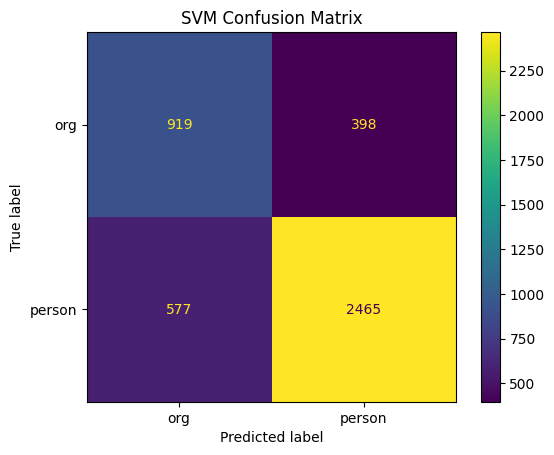

In [7]:

# T9: Support Vector Machine Classification

from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

# Build SVM pipeline
svm_model = Pipeline([
    ('preprocessor', make_preprocessor()),
    ('classifier', LinearSVC(
        C=1.0,
        class_weight='balanced',
        random_state=42,
        max_iter=10000
    ))
])

# Train the model
svm_model.fit(X_train, y_train)

# Predict
y_pred_svm = svm_model.predict(X_test)

# Evaluate
print("SVM Accuracy:",
      round(accuracy_score(y_test, y_pred_svm) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_svm, zero_division=0
))

# Confusion matrix
cm_svm = confusion_matrix(
    y_test, y_pred_svm, labels=svm_model.classes_
)

ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=svm_model.classes_
).plot()

plt.title('SVM Confusion Matrix')
plt.show()


In [8]:

# Compare Naive Bayes and SVM

from sklearn.metrics import precision_score, recall_score, f1_score

results = []

for model_name, predictions in [
    ('Naive Bayes', y_pred_nb),
    ('SVM', y_pred_svm)
]:
    results.append({
        'Model': model_name,
        'Accuracy': round(accuracy_score(y_test, predictions), 4),
        'Precision (weighted)': round(
            precision_score(y_test, predictions,
                            average='weighted', zero_division=0), 4),
        'Recall (weighted)': round(
            recall_score(y_test, predictions,
                         average='weighted', zero_division=0), 4),
        'F1-score (weighted)': round(
            f1_score(y_test, predictions,
                     average='weighted', zero_division=0), 4)
    })

comparison = pd.DataFrame(results)
print(comparison)


         Model  Accuracy  Precision (weighted)  Recall (weighted)  \
0  Naive Bayes    0.3478                0.7205             0.3478   
1          SVM    0.7763                0.7865             0.7763   

   F1-score (weighted)  
0               0.2392  
1               0.7801  
